In [18]:
import pandas as pd
import numpy as np
from pathlib import Path
DATA_DIR = next((p/'converted_xlsx' for p in [Path.cwd(), *Path.cwd().parents] if (p/'converted_xlsx').is_dir()), None)
if DATA_DIR is None:
    raise FileNotFoundError('converted_xlsx')
OUTPUT_DIR = DATA_DIR.parent/'proposal_analysis'/'analysis_2024_outputs'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

In [19]:
path24 = "converted_xlsx/24pubdb.xlsx"
path25 = "converted_xlsx/25pubdb.xlsx"

print raw data set

In [20]:
accident24 = pd.read_excel(
    path24, sheet_name="accident2024",
    usecols="A:M", keep_default_na=False
)

vehicle24 = pd.read_excel(
    path24, sheet_name="vehicle2024",
    usecols="A:F", keep_default_na=False
)

casualty24 = pd.read_excel(
    path24, sheet_name="casualty2024",
    usecols="A:H", keep_default_na=False
)

accident25 = pd.read_excel(
    path25, sheet_name="accident2025",
    usecols="A:M", keep_default_na=False
)

vehicle25 = pd.read_excel(
    path25, sheet_name="vehicle2025",
    usecols="A:F", keep_default_na=False
)

casualty25 = pd.read_excel(
    path25, sheet_name="casualty2025",
    usecols="A:H", keep_default_na=False
)

for name, table in {
    "Accident": accident24,
    "Vehicle": vehicle24,
    "Casualty": casualty24
}.items():
    print(f"2024 {name} data set: {table.shape[0]:,} row, {table.shape[1]} col")
    display(table.head())


for name, table in {
    "Accident": accident25,
    "Vehicle": vehicle25,
    "Casualty": casualty25
}.items():
    print(f"2025 {name} data set: {table.shape[0]:,} row, {table.shape[1]} col")
    display(table.head())

2024 Accident data set: 18,354 row, 13 col


,Serial,Severity,District Council District,Hit and Run,Weather,Rain,Natural Light,Junction Control,Road Classification,Vehicle Movements,Type of Collision,No. of Vehicles Involved,No. of Casualties
0,1,3,WCH,2,1,1,3,6,2,1,1,1,3
1,2,3,WCH,2,1,1,3,6,2,1,1,1,1
2,3,3,WCH,2,1,1,3,6,2,1,4,1,1
3,4,3,KT,2,1,1,3,6,2,5,2,3,2
4,5,3,SK,2,1,1,3,2,2,2,2,2,1


2024 Vehicle data set: 31,315 row, 6 col


,Serial,Driver Age,Driver Sex,Year of Manufacture,Severity of Accident,Vehicle Class
0,1,40,1,2009,3,1
1,2,59,1,2021,3,9
2,3,53,1,2018,3,1
3,4,30,1,2022,3,2
4,4,34,1,2013,3,2


2024 Casualty data set: 23,656 row, 8 col


...

,Serial,Severity,District Council District,Hit and Run,Weather,Rain,Natural Light,Junction Control,Road Classification,Vehicle Movements,Type of Collision,No. of Vehicles Involved,No. of Casualties
0,1,3,S,2,1,1,3,6,2,1,4,1,1
1,2,3,SK,2,1,1,3,6,2,2,2,2,1
2,3,3,SK,2,1,1,3,6,2,1,4,1,1
3,4,1,YTM,2,1,1,3,6,2,5,2,6,7
4,5,3,YL,2,1,1,3,6,2,6,2,3,5


2025 Vehicle data set: 29,595 row, 6 col


,Serial,Driver Age,Driver Sex,Year of Manufacture,Severity of Accident,Vehicle Class
0,1,22,1,2019,3,1
1,2,26,1,2011,3,9
2,2,47,1,2017,3,2
3,3,56,1,NA,3,10
4,4,30,1,2005,1,2


2025 Casualty data set: 21,815 row, 8 col


,Serial,Casualty Age,Casualty Sex,Degree of Injury,Role of Casualty,Location of Injury,Pedestrian Action,Vehicle Class of Driver or Passenger Casualty
0,1,22,1,3,1,DE,NA,1
1,2,26,1,3,1,B,NA,9
2,3,56,1,3,1,B,NA,10
3,4,30,1,1,1,A,NA,2
4,4,33,1,1,2,A,NA,2


data info for 2024 and 2025

In [21]:
for table in [accident24, vehicle24, casualty24]:
    table.replace(r"^\s*$", np.nan, regex=True, inplace=True)
    display(table.describe())
    # display(table.info())
    
for table in [accident25, vehicle25, casualty25]:
    table.replace(r"^\s*$", np.nan, regex=True, inplace=True)
    display(table.describe())

,Serial,Severity,Hit and Run,Weather,Rain,Natural Light,Junction Control,Road Classification,Vehicle Movements,Type of Collision,No. of Vehicles Involved,No. of Casualties
count,18354.000000,18354.000000,18354.000000,18354.000000,18354.000000,18354.000000,18354.00000,18354.000000,18354.000000,18354.000000,18354.000000,18354.000000
mean,9177.500000,2.950038,1.989321,1.065054,1.143674,1.669064,5.49477,1.999782,1.957448,2.367113,1.706168,1.288874
std,5298.487756,0.237725,0.102788,0.550819,0.737124,1.069326,1.37229,0.014761,1.125769,0.980727,0.681198,0.812920
min,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.00000,1.000000,1.000000,1.000000,1.000000,1.000000
25%,4589.250000,3.000000,2.000000,1.000000,1.000000,1.000000,6.00000,2.000000,1.000000,2.000000,1.000000,1.000000
50%,9177.500000,3.000000,2.000000,1.000000,1.000000,1.000000,6.00000,2.000000,2.000000,2.000000,2.000000,1.000000
75%,13765.750000,3.000000,2.000000,1.000000,1.000000,3.000000,6.00000,2.000000,2.000000,3.000000,2.000000,1.000000
max,18354.000000,3.000000,2.000000,9.000000,9.000000,9.000000,6.00000,2.000000,7.000000,4.000000,11.000000,23.000000


,Serial,Driver Age,Driver Sex,Severity of Accident,Vehicle Class
count,31315.000000,31315.000000,31315.000000,31315.000000,31315.000000
mean,9266.282325,68.003002,1.244100,2.955421,4.615200
std,5282.331563,142.037272,1.130131,0.224182,3.274429
min,1.000000,2.000000,1.000000,1.000000,1.000000
25%,4734.500000,35.000000,1.000000,3.000000,2.000000
50%,9266.000000,46.000000,1.000000,3.000000,3.000000
75%,13857.000000,60.000000,1.000000,3.000000,9.000000
max,18354.000000,999.000000,9.000000,3.000000,13.000000


,Serial,Casualty Age,Casualty Sex,Degree of Injury,Role of Casualty
count,23656.000000,23656.000000,23656.000000,23656.000000,23656.000000
mean,9332.003001,53.919809,1.301657,2.958911,1.517289
std,5264.383787,101.441589,0.493773,0.216431,0.689227
min,1.000000,0.000000,1.000000,1.000000,1.000000
25%,4810.750000,31.000000,1.000000,3.000000,1.000000
50%,9507.000000,42.000000,1.000000,3.000000,1.000000
75%,13925.250000,56.000000,2.000000,3.000000,2.000000
max,18354.000000,999.000000,9.000000,3.000000,3.000000


,Serial,Severity,Hit and Run,Weather,Rain,Natural Light,Junction Control,Road Classification,Vehicle Movements,Type of Collision,No. of Vehicles Involved,No. of Casualties
count,17320.000000,17320.000000,17320.000000,17320.000000,17320.000000,17320.000000,17320.000000,17320.000000,17320.000000,17320.000000,17320.000000,17320.000000
mean,8660.500000,2.962413,1.990647,1.042667,1.114781,1.628811,5.570208,1.998672,1.960912,2.372748,1.708718,1.259527
std,4999.997667,0.216333,0.096262,0.415744,0.633742,1.005172,1.283900,0.036418,1.129180,0.993760,0.682592,0.787571
min,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
25%,4330.750000,3.000000,2.000000,1.000000,1.000000,1.000000,6.000000,2.000000,1.000000,2.000000,1.000000,1.000000
50%,8660.500000,3.000000,2.000000,1.000000,1.000000,1.000000,6.000000,2.000000,2.000000,2.000000,2.000000,1.000000
75%,12990.250000,3.000000,2.000000,1.000000,1.000000,3.000000,6.000000,2.000000,2.000000,3.000000,2.000000,1.000000
max,17320.000000,3.000000,2.000000,9.000000,9.000000,9.000000,6.000000,2.000000,7.000000,4.000000,12.000000,23.000000


,Serial,Driver Age,Driver Sex,Severity of Accident,Vehicle Class
count,29595.000000,29595.000000,29595.000000,29595.000000,29595.000000
mean,8724.538436,68.050786,1.242609,2.964622,4.605136
std,4973.594624,143.101904,1.093674,0.210070,3.299360
min,1.000000,1.000000,1.000000,1.000000,1.000000
25%,4476.500000,35.000000,1.000000,3.000000,2.000000
50%,8697.000000,46.000000,1.000000,3.000000,3.000000
75%,13043.500000,59.000000,1.000000,3.000000,9.000000
max,17320.000000,999.000000,9.000000,3.000000,13.000000


,Serial,Casualty Age,Casualty Sex,Degree of Injury,Role of Casualty
count,21815.000000,21815.000000,21815.000000,21815.000000,21815.000000
mean,8812.844923,52.569975,1.308182,2.967499,1.499656
std,4969.493671,93.348078,0.514353,0.200389,0.694572
min,1.000000,0.000000,1.000000,1.000000,1.000000
25%,4555.500000,31.000000,1.000000,3.000000,1.000000
50%,8933.000000,42.000000,1.000000,3.000000,1.000000
75%,13120.500000,57.000000,2.000000,3.000000,2.000000
max,17320.000000,999.000000,9.000000,3.000000,3.000000


normalize date and retrieve code book

In [22]:
def normalize_code(value):
    # normalizing dtype avoiding 1,1.0,"1"
    if pd.isna(value):
        return None

    text = str(value).strip()

    try:
        number = float(text)
        if np.isfinite(number) and number.is_integer():
            return str(int(number))
    except ValueError:
        pass

    return text


def load_codebook(path, sheet_name):
    codebook = pd.read_excel(
        path,
        sheet_name=sheet_name,
        keep_default_na=False
    )

    codebook["Field name"] = (
        codebook["Field name"]
        .replace(r"^\s*$", np.nan, regex=True)
        .ffill()
    )

    # remove empty space
    codebook = codebook[
        codebook["Code"].notna()
        & codebook["Code"].astype(str).str.strip().ne("")
    ].copy()

    mappings = {}

    for field, group in codebook.groupby("Field name"):
        mappings[field] = {
            normalize_code(code): str(description).strip()
            for code, description in zip(
                group["Code"],
                group["Description"]
            )
        }

    return mappings

code_path24 = "converted_xlsx/24codee.xlsx"
accident_maps = load_codebook(code_path24, "Accident")
vehicle_maps = load_codebook(code_path24, "Vehicle")
casualty_maps = load_codebook(code_path24, "Casualty")

print(vehicle_maps["Vehicle Class"])

{'1': 'Motorcycle', '2': 'Private car', '3': 'Public light bus', '4': 'Light goods vehicle', '5': 'Medium goods vehicle', '6': 'Heavy goods vehicle', '7': 'Franchised public bus', '8': 'Non-franchised public bus', '9': 'Taxi', '10': 'Bicycle', '11': 'Tram', '12': 'Light rail vehicle', '13': 'Others (incl. unknown)'}


In [23]:
def replace_codes_with_descriptions(table, mappings, aliases=None):
    result = table.copy()
    aliases = aliases or {}

    for field, mapping in mappings.items():
        column = aliases.get(field, field)

        if column not in result.columns:
            continue

        # replce 999 with np.nan
        if column in ["Driver Age", "Casualty Age"]:
            result[column] = (
                pd.to_numeric(result[column], errors="coerce")
                .replace(999, np.nan)
                .astype("Int64")
            )
            continue

        def decode_value(value):
            code = normalize_code(value)

            if code is None or code == "":
                return pd.NA

            # mapping value with codebook
            if code in mapping:
                return mapping[code]

            if code in mapping.values():
                return code

            # location of inj col replace
            if column == "Location of Injury":
                if set(code).issubset(set("ABCDE")):
                    return " + ".join(
                        mapping[letter]
                        for letter in dict.fromkeys(code)
                    )

                parts = code.split(" + ")
                body_descriptions = {
                    mapping[letter] for letter in "ABCDE"
                }

                if all(part in body_descriptions for part in parts):
                    return code


            raise ValueError(
                f"{column} undecode value:{value!r}"
            )

        # replace origin col 
        result[column] = (
            result[column]
            .map(decode_value)
            .astype("string")
        )

    return result

decode code book to each dataset

In [24]:
converted_accident24 = replace_codes_with_descriptions(
    accident24,
    accident_maps,
    aliases={"Severity of Accident": "Severity"}
)

converted_vehicle24 = replace_codes_with_descriptions(
    vehicle24,
    vehicle_maps
)

converted_casualty24 = replace_codes_with_descriptions(
    casualty24,
    casualty_maps,
    aliases={"Pedestrian action": "Pedestrian Action"}
)

accident24, vehicle24, casualty24 = (
    converted_accident24,
    converted_vehicle24,
    converted_casualty24
)

converted_accident25 = replace_codes_with_descriptions(
    accident25,
    accident_maps,
    aliases={"Severity of Accident": "Severity"}
)

converted_vehicle25 = replace_codes_with_descriptions(
    vehicle25,
    vehicle_maps
)

converted_casualty25 = replace_codes_with_descriptions(
    casualty25,
    casualty_maps,
    aliases={"Pedestrian action": "Pedestrian Action"}
)

accident25, vehicle25, casualty25 = (
    converted_accident25,
    converted_vehicle25,
    converted_casualty25
)

normalize col name in each table, clean driver age 

In [25]:
accident24.head()

,Serial,Severity,District Council District,Hit and Run,Weather,Rain,Natural Light,Junction Control,Road Classification,Vehicle Movements,Type of Collision,No. of Vehicles Involved,No. of Casualties
0,1,Slight,Wan Chai,No,Clear,Not raining,Dark,Not junction,Non-private road,One moving vehicle,Vehicle collision with Pedestrian,1,3
1,2,Slight,Wan Chai,No,Clear,Not raining,Dark,Not junction,Non-private road,One moving vehicle,Vehicle collision with Pedestrian,1,1
2,3,Slight,Wan Chai,No,Clear,Not raining,Dark,Not junction,Non-private road,One moving vehicle,Vehicle without collision,1,1
3,4,Slight,Kwun Tong,No,Clear,Not raining,Dark,Not junction,Non-private road,> 2 moving vehicles - from same direction,Vehicle collision with Vehicle,3,2
4,5,Slight,Sai Kung,No,Clear,Not raining,Dark,Stop (halt),Non-private road,Two moving vehicles - from same direction,Vehicle collision with Vehicle,2,1


In [26]:
vehicle24.head()

,Serial,Driver Age,Driver Sex,Year of Manufacture,Severity of Accident,Vehicle Class
0,1,40,Male,2009,Slight,Motorcycle
1,2,59,Male,2021,Slight,Taxi
2,3,53,Male,2018,Slight,Motorcycle
3,4,30,Male,2022,Slight,Private car
4,4,34,Male,2013,Slight,Private car


In [27]:
casualty24.head()

,Serial,Casualty Age,Casualty Sex,Degree of Injury,Role of Casualty,Location of Injury,Pedestrian Action,Vehicle Class of Driver or Passenger Casualty
0,1,41,Male,Slightly Injured,Pedestrian,Upper trunk,Crossing from near-side,Not Applicable (i.e. non-driver and non-passen...
1,1,40,Male,Slightly Injured,Driver,Upper trunk,Not Applicable (i.e. non-pedestrian),Motorcycle
2,1,49,Female,Slightly Injured,Passenger,Arms,Not Applicable (i.e. non-pedestrian),Motorcycle
3,2,32,Female,Slightly Injured,Pedestrian,Legs,Crossing from off-side,Not Applicable (i.e. non-driver and non-passen...
4,3,53,Male,Slightly Injured,Driver,Upper trunk,Not Applicable (i.e. non-pedestrian),Motorcycle


check converted dataset and unique value for each col

In [28]:
def unique_summary(df):
    return pd.DataFrame([
        {
            "Column": col,
            "Unique count": df[col].nunique(dropna=False),
            "Missing count": df[col].isna().sum(),
            "Values": (
                "Identifier — omitted"
                if col == "Serial"
                else repr(df[col].unique().tolist())
            )
        }
        for col in df.columns
    ])

with pd.option_context(
    "display.max_rows", None,
    "display.max_colwidth", None
):
    display(unique_summary(accident24))
    display(unique_summary(vehicle24))
    display(unique_summary(casualty24))

,Column,Unique count,Missing count,Values
0,Serial,18354,0,Identifier — omitted
1,Severity,3,0,"['Slight', 'Serious', 'Fatal']"
2,District Council District,18,0,"['Wan Chai', 'Kwun Tong', 'Sai Kung', 'Tuen Mun', 'Kwai Tsing', 'Central and Western', 'Eastern', 'Yau Tsim Mong', 'Southern', 'Islands', 'Kowloon City', 'Wong Tai Sin', 'Tai Po', 'Sham Shui Po', 'Sha Tin', 'North', 'Yuen Long', 'Tsuen Wan']"
3,Hit and Run,2,0,"['No', 'Yes']"
4,Weather,5,0,"['Clear', 'Dull', 'Not known', 'Fog/mist', 'Strong wind']"
5,Rain,4,0,"['Not raining', 'Light rain', 'Not known', 'Heavy rain']"
6,Natural Light,4,0,"['Dark', 'Dawn/Dusk', 'Daylight', 'Not known']"
7,Junction Control,5,0,"['Not junction', 'Stop (halt)', 'No control', 'Traffic signal', 'Give way (slow)']"
8,Road Classification,2,0,"['Non-private road', 'Private road']"
9,Vehicle Movements,7,0,"['One moving vehicle', '> 2 moving vehicles - from same direction', 'Two moving vehicles - from same direction', 'Two moving vehicles - from different roads', 'Two moving vehicles - from opposite direction', '> 2 moving vehicles - from opposite direction', '>2 moving vehicles - from different roads']"


,Column,Unique count,Missing count,Values
0,Serial,18354,0,Identifier — omitted
1,Driver Age,92,705,"[40, 59, 53, 30, 34, 28, 47, 55, 13, 51, 33, 72, 57, 60, 73, 68, 36, 65, 42, 44, 67, 75, 62, 24, 37, 70, 43, <NA>, 29, 32, 64, 56, 61, 23, 27, 21, 49, 58, 41, 54, 69, 66, 35, 50, 31, 39, 63, 38, 52, 77, 26, 48, 46, 76, 25, 78, 74, 22, 45, 79, 71, 87, 20, 81, 80, 19, 4, 16, 7, 15, 17, 88, 91, 18, 84, 83, 11, 6, 5, 12, 14, 10, 86, 85, 8, 90, 9, 3, 82, 89, 2, 95]"
2,Driver Sex,3,0,"['Male', 'Female', 'Not known']"
3,Year of Manufacture,43,0,"[2009, 2021, 2018, 2022, 2013, 2015, 2023, 2005, 'NA', 2017, 2011, 2016, 2012, 2020, 2019, 2014, 2010, 2008, 2001, 2007, 2004, 2006, 2000, 2002, 2003, 1997, 1993, 2024, 1990, 1995, 1998, 1999, 1996, 1959, 1992, 1994, 1991, 1985, 1965, 1966, 1988, 1989, 1984]"
4,Severity of Accident,3,0,"['Slight', 'Serious', 'Fatal']"
5,Vehicle Class,13,0,"['Motorcycle', 'Taxi', 'Private car', 'Light goods vehicle', 'Bicycle', 'Franchised public bus', 'Medium goods vehicle', 'Public light bus', 'Heavy goods vehicle', 'Others (incl. unknown)', 'Tram', 'Non-franchised public bus', 'Light rail vehicle']"


,Column,Unique count,Missing count,Values
0,Serial,18354,0,Identifier — omitted
1,Casualty Age,100,262,"[41, 40, 49, 32, 53, 34, 28, 47, 55, 74, 51, 77, 30, 65, 67, 84, 61, 56, 36, 42, 44, 62, 24, 46, 73, 59, 26, 29, 33, 43, 88, 23, 27, 21, 58, 31, 45, 66, 35, 64, 50, 39, 37, 38, 20, 76, 80, 54, 5, 72, 25, 57, 22, 15, 63, 68, 13, 87, 14, 52, <NA>, 83, 60, 7, 1, 48, 75, 71, 69, 12, 81, 11, 79, 70, 19, 6, 93, 91, 85, 17, 89, 18, 10, 2, 86, 9, 94, 16, 0, 8, 4, 90, 78, 3, 82, 98, 92, 96, 97, 95]"
2,Casualty Sex,3,0,"['Male', 'Female', 'Not known']"
3,Degree of Injury,3,0,"['Slightly Injured', 'Seriously Injured', 'Killed']"
4,Role of Casualty,3,0,"['Pedestrian', 'Driver', 'Passenger']"
5,Location of Injury,31,0,"['Upper trunk', 'Arms', 'Legs', 'Head', 'Head + Upper trunk', 'Lower trunk + Arms', 'Head + Arms', 'Upper trunk + Arms', 'Head + Arms + Legs', 'Upper trunk + Lower trunk', 'Arms + Legs', 'Upper trunk + Arms + Legs', 'Head + Legs', 'Head + Upper trunk + Legs', 'Lower trunk', 'Lower trunk + Arms + Legs', 'Lower trunk + Legs', 'Head + Upper trunk + Arms', 'Upper trunk + Legs', 'Head + Upper trunk + Arms + Legs', 'Upper trunk + Lower trunk + Arms', 'Head + Upper trunk + Lower trunk + Arms + Legs', 'Head + Lower trunk + Arms + Legs', 'Head + Lower trunk', 'Upper trunk + Lower trunk + Legs', 'Head + Upper trunk + Lower trunk + Arms', 'Upper trunk + Lower trunk + Arms + Legs', 'Head + Lower trunk + Arms', 'Head + Upper trunk + Lower trunk', 'Head + Lower trunk + Legs', 'Head + Upper trunk + Lower trunk + Legs']"
6,Pedestrian Action,13,0,"['Crossing from near-side', 'Not Applicable (i.e. non-pedestrian)', 'Crossing from off-side', 'Walking - back to traffic', 'Walking - facing traffic', 'Standing', 'Boarding vehicle', 'Not known', 'Alighting from vehicle', 'Playing', 'Other working', 'Working at a vehicle', 'Falling or jumping from vehicle']"
7,Vehicle Class of Driver or Passenger Casualty,14,0,"['Not Applicable (i.e. non-driver and non-passenger)', 'Motorcycle', 'Private car', 'Light goods vehicle', 'Taxi', 'Franchised public bus', 'Medium goods vehicle', 'Bicycle', 'Public light bus', 'Others (incl. unknown)', 'Tram', 'Non-franchised public bus', 'Heavy goods vehicle', 'Light rail vehicle']"


In [35]:
with pd.option_context(
    "display.max_rows", None,
    "display.max_colwidth", None
):
    display(unique_summary(accident25))
    display(unique_summary(vehicle25))
    display(unique_summary(casualty25))

,Column,Unique count,Missing count,Values
0,Serial,17320,0,Identifier — omitted
1,Severity,3,0,"['Slight', 'Fatal', 'Serious']"
2,District Council District,18,0,"['Southern', 'Sai Kung', 'Yau Tsim Mong', 'Yuen Long', 'Kwai Tsing', 'Islands', 'Central and Western', 'Wan Chai', 'Eastern', 'Kwun Tong', 'Wong Tai Sin', 'Tai Po', 'Kowloon City', 'Sha Tin', 'Sham Shui Po', 'North', 'Tuen Mun', 'Tsuen Wan']"
3,Hit and Run,2,0,"['No', 'Yes']"
4,Weather,5,0,"['Clear', 'Dull', 'Fog/mist', 'Not known', 'Strong wind']"
5,Rain,4,0,"['Not raining', 'Light rain', 'Heavy rain', 'Not known']"
6,Natural Light,4,0,"['Dark', 'Dawn/Dusk', 'Daylight', 'Not known']"
7,Junction Control,5,0,"['Not junction', 'No control', 'Traffic signal', 'Give way (slow)', 'Stop (halt)']"
8,Road Classification,2,0,"['Non-private road', 'Private road']"
9,Vehicle Movements,7,0,"['One moving vehicle', 'Two moving vehicles - from same direction', '> 2 moving vehicles - from same direction', '> 2 moving vehicles - from opposite direction', 'Two moving vehicles - from different roads', 'Two moving vehicles - from opposite direction', '>2 moving vehicles - from different roads']"


,Column,Unique count,Missing count,Values
0,Serial,17320,0,Identifier — omitted
1,Driver Age,93,676,"[22, 26, 47, 56, 30, 65, 68, 36, 58, 43, 44, 31, 21, 20, 62, 35, <NA>, 49, 54, 38, 57, 24, 55, 69, 33, 50, 60, 14, 29, 32, 42, 59, 64, 17, 39, 27, 53, 74, 28, 48, 46, 66, 63, 67, 45, 78, 25, 61, 73, 34, 40, 51, 41, 70, 76, 37, 52, 23, 19, 77, 71, 75, 86, 72, 80, 16, 88, 18, 79, 83, 10, 91, 89, 12, 85, 90, 15, 87, 81, 5, 11, 13, 9, 4, 6, 8, 84, 7, 3, 82, 95, 1, 2]"
2,Driver Sex,3,0,"['Male', 'Not known', 'Female']"
3,Year of Manufacture,42,0,"[2019, 2011, 2017, 'NA', 2005, 2021, 2023, 2022, 2013, 2007, 2018, 2004, 2015, 2009, 2016, 2024, 2008, 2012, 2010, 2020, 2014, 2001, 1994, 2006, 2003, 2002, 1993, 1984, 2025, 2000, 1998, 1990, 1997, 1995, 1999, 1996, 1991, 1992, 1975, 1989, 1978, 1985]"
4,Severity of Accident,3,0,"['Slight', 'Fatal', 'Serious']"
5,Vehicle Class,13,0,"['Motorcycle', 'Taxi', 'Private car', 'Bicycle', 'Others (incl. unknown)', 'Light goods vehicle', 'Medium goods vehicle', 'Franchised public bus', 'Public light bus', 'Non-franchised public bus', 'Heavy goods vehicle', 'Tram', 'Light rail vehicle']"


,Column,Unique count,Missing count,Values
0,Serial,17320,0,Identifier — omitted
1,Casualty Age,102,203,"[22, 26, 56, 30, 33, 21, 25, 34, 23, 20, <NA>, 44, 31, 49, 51, 50, 16, 35, 54, 38, 24, 46, 55, 69, 52, 43, 14, 81, 42, 57, 17, 65, 39, 73, 58, 28, 27, 63, 66, 32, 60, 53, 61, 47, 45, 87, 41, 68, 79, 67, 88, 48, 36, 8, 11, 40, 93, 12, 59, 13, 2, 76, 82, 4, 3, 78, 86, 1, 90, 5, 29, 75, 77, 80, 85, 62, 18, 37, 64, 71, 70, 92, 72, 83, 74, 89, 84, 19, 7, 94, 10, 91, 9, 6, 95, 15, 103, 0, 97, 98, 101, 99]"
2,Casualty Sex,3,0,"['Male', 'Female', 'Not known']"
3,Degree of Injury,3,0,"['Slightly Injured', 'Killed', 'Seriously Injured']"
4,Role of Casualty,3,0,"['Driver', 'Passenger', 'Pedestrian']"
5,Location of Injury,31,0,"['Arms + Legs', 'Upper trunk', 'Head', 'Head + Upper trunk + Legs', 'Head + Upper trunk + Arms', 'Head + Arms', 'Head + Upper trunk', 'Arms', 'Legs', 'Upper trunk + Arms', 'Head + Arms + Legs', 'Upper trunk + Arms + Legs', 'Upper trunk + Legs', 'Lower trunk', 'Lower trunk + Legs', 'Head + Legs', 'Upper trunk + Lower trunk', 'Head + Upper trunk + Lower trunk', 'Head + Upper trunk + Arms + Legs', 'Head + Lower trunk + Arms', 'Lower trunk + Arms + Legs', 'Head + Upper trunk + Lower trunk + Legs', 'Lower trunk + Arms', 'Upper trunk + Lower trunk + Arms + Legs', 'Head + Lower trunk', 'Head + Lower trunk + Legs', 'Head + Upper trunk + Lower trunk + Arms + Legs', 'Upper trunk + Lower trunk + Arms', 'Upper trunk + Lower trunk + Legs', 'Head + Upper trunk + Lower trunk + Arms', 'Head + Lower trunk + Arms + Legs']"
6,Pedestrian Action,13,0,"['Not Applicable (i.e. non-pedestrian)', 'Crossing from off-side', 'Crossing from near-side', 'Walking - back to traffic', 'Standing', 'Walking - facing traffic', 'Not known', 'Other working', 'Boarding vehicle', 'Working at a vehicle', 'Playing', 'Alighting from vehicle', 'Falling or jumping from vehicle']"
7,Vehicle Class of Driver or Passenger Casualty,14,0,"['Motorcycle', 'Taxi', 'Bicycle', 'Private car', 'Not Applicable (i.e. non-driver and non-passenger)', 'Light goods vehicle', 'Franchised public bus', 'Non-franchised public bus', 'Others (incl. unknown)', 'Public light bus', 'Medium goods vehicle', 'Tram', 'Heavy goods vehicle', 'Light rail vehicle']"


## data analyze

In [29]:
from IPython.display import display, SVG
import html, json
for frame, col in [(vehicle24, 'Driver Age'), (casualty24, 'Casualty Age')]:
    frame[col] = pd.to_numeric(frame[col], errors='coerce').replace(999, np.nan).astype('Int64')
vehicle24['Year of Manufacture'] = pd.to_numeric(vehicle24['Year of Manufacture'], errors='coerce').astype('Int64')
assert not vehicle24['Year of Manufacture'].gt(2024).fillna(False).any()
vehicle24['Vehicle Age'] = 2024 - vehicle24['Year of Manufacture']
accident24['severe'] = accident24['Severity'].isin(['Fatal', 'Serious']).astype(int)

def bar_chart(series, title, subtitle, filename, percent=False):
    values = series.astype(float)
    width, left = 1120, 360
    height = 115 + 32 * len(values)
    scale = max(values.max(), 1)
    parts = [f'<svg xmlns="http://www.w3.org/2000/svg" width="{width}" height="{height}" viewBox="0 0 {width} {height}">', '<rect width="100%" height="100%" fill="white"/>', '<g font-family="Arial, sans-serif">', f'<text x="20" y="30" font-size="21" font-weight="bold">{html.escape(title)}</text>', f'<text x="20" y="57" font-size="13" fill="#52627a">{html.escape(subtitle)}</text>']
    for i, (label, value) in enumerate(values.items()):
        y = 82 + i*32; length = value/scale*650
        label_value = f'{value:.2f}%' if percent else f'{value:,.0f}'
        parts += [f'<text x="20" y="{y+15}" font-size="13">{html.escape(str(label))}</text>', f'<rect x="{left}" y="{y}" width="{length:.2f}" height="20" rx="3" fill="#2563eb"/>', f'<text x="{left+length+8:.2f}" y="{y+15}" font-size="13">{label_value}</text>']
    parts.append('</g></svg>')
    svg = ''.join(parts)
    (OUTPUT_DIR/filename).write_text(svg, encoding='utf-8')
    display(SVG(svg))


accident24 = replace_codes_with_descriptions(accident24, accident_maps, aliases={'Severity of Accident':'Severity'})
vehicle24 = replace_codes_with_descriptions(vehicle24, vehicle_maps)
casualty24 = replace_codes_with_descriptions(casualty24, casualty_maps, aliases={'Pedestrian action':'Pedestrian Action'})
assert set(accident24['District Council District'].dropna()) <= set(accident_maps['District Council District'].values())
assert set(accident24.Severity.dropna()) <= {'Fatal','Serious','Slight'}
accident24['severe'] = accident24.Severity.isin(['Fatal','Serious']).astype(int)
import math
COLORS=['#2563eb','#f97316','#10b981','#a855f7','#eab308','#ec4899','#64748b']
def canvas(title, subtitle, height=520):
    return [f'<svg xmlns="http://www.w3.org/2000/svg" width="1100" height="{height}" viewBox="0 0 1100 {height}"><rect width="100%" height="100%" fill="white"/><g font-family="Arial, sans-serif">',f'<text x="25" y="32" font-size="22" font-weight="bold">{html.escape(title)}</text>',f'<text x="25" y="58" font-size="13" fill="#52627a">{html.escape(subtitle)}</text>']
def text_at(x,y,label,size=13,color='#17243b'):
    return f'<text x="{x}" y="{y}" font-size="{size}" fill="{color}">{html.escape(str(label))}</text>'
def finish(parts,filename):
    parts.append('</g></svg>');svg=''.join(parts)
    (OUTPUT_DIR/filename).write_text(svg,encoding='utf-8');display(SVG(svg))


### Accident Table · Figure 1: Number of Accidents by Administrative District

Select **District Council District**. Count accident records for each district to identify areas with high accident concentrations; this is not a risk ranking adjusted for traffic volume.

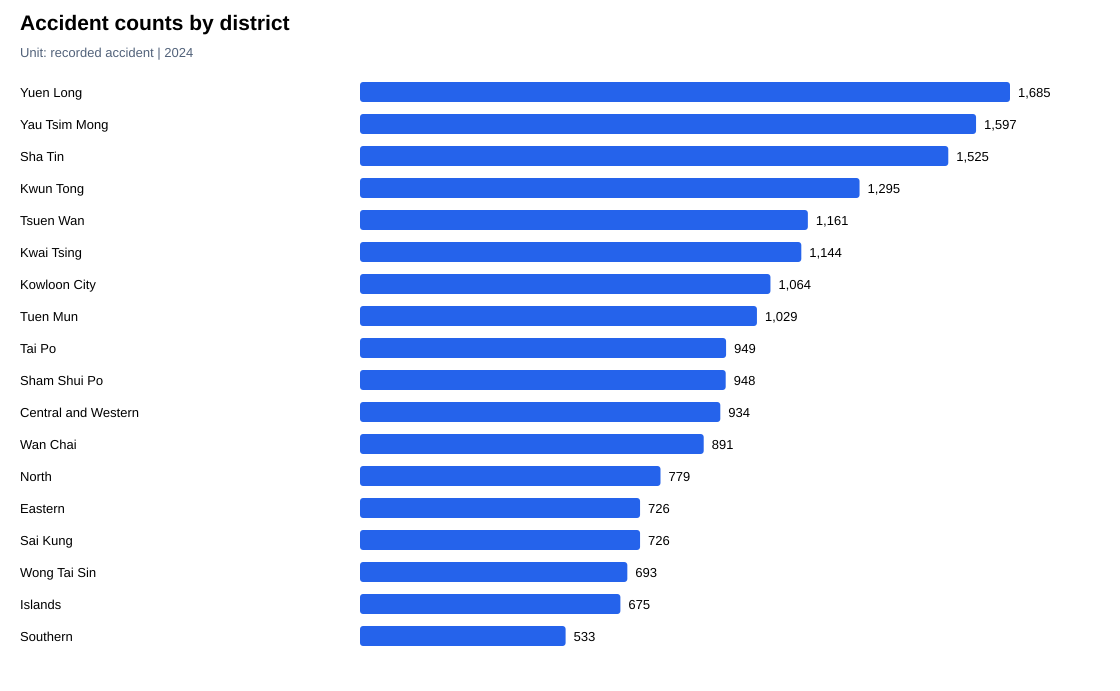

In [30]:
district_counts=accident24['District Council District'].value_counts()
# display(district_counts.to_frame('Accidents'))
bar_chart(district_counts,'Accident counts by district','Unit: recorded accident | 2024','01_accident_district.svg')

### Accident Table · Figure 2: Heatmap of Lighting Condition vs. Accident Severity

This plot differs from the administrative district accident count chart: it compares the breakdown of Fatal / Serious / Slight accidents under different lighting conditions. Each row uses the total number of accidents for that lighting condition as the denominator, and each cell shows the corresponding proportion. Darker colours represent higher proportions. The dataset does not contain an hour field; lighting categories are not treated as a time series.

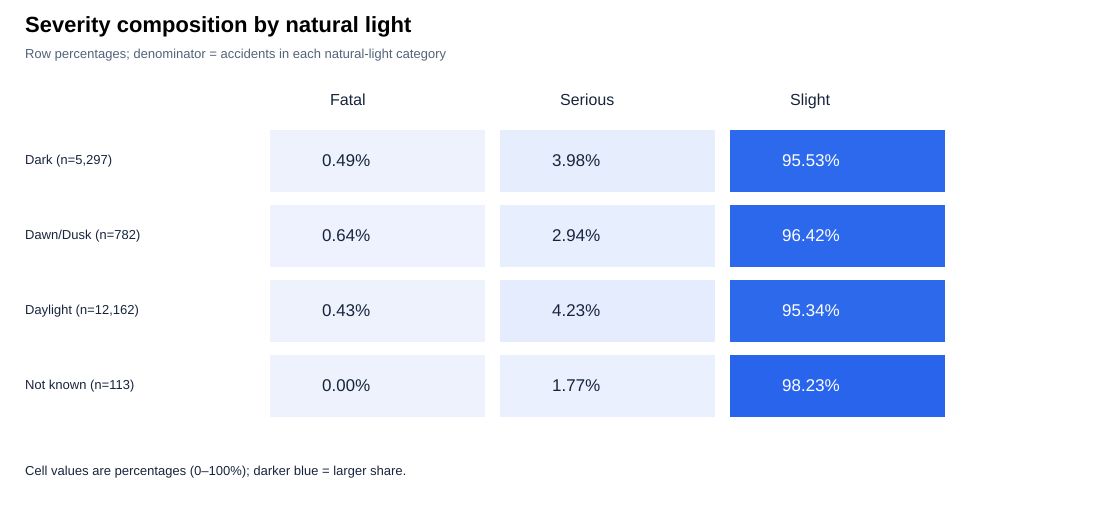

In [31]:
tab=pd.crosstab(accident24['Natural Light'],accident24.Severity).reindex(columns=['Fatal','Serious','Slight'],fill_value=0)
pct=tab.div(tab.sum(axis=1),axis=0)*100
parts=canvas('Severity composition by natural light','Row percentages; denominator = accidents in each natural-light category')
for j,col in enumerate(pct.columns):parts.append(text_at(330+j*230,105,col,16))
for i,(label,row) in enumerate(pct.iterrows()):
    y=130+i*75;parts.append(text_at(25,y+34,f'{label} (n={tab.loc[label].sum():,})'))
    for j,value in enumerate(row):
        x=270+j*230;opacity=.08+.92*value/100
        parts.append(f'<rect x="{x}" y="{y}" width="215" height="62" fill="#2563eb" fill-opacity="{opacity}"/>')
        parts.append(text_at(x+52,y+36,f'{value:.2f}%',17,'white' if value>60 else '#17243b'))
parts.append(text_at(25,475,'Cell values are percentages (0–100%); darker blue = larger share.'))
finish(parts,'02_accident_light_heatmap.svg')


### Vehicle Table · Figure 1: Pie Chart of Involved Vehicle Types

Shows the composition of records for vehicles involved in accidents. The six most frequent vehicle types are retained, and all other types are grouped as "Remaining classes", which is separate from the original "Others" category. Each sector legend displays the count and percentage, with the denominator being all records of involved vehicles.

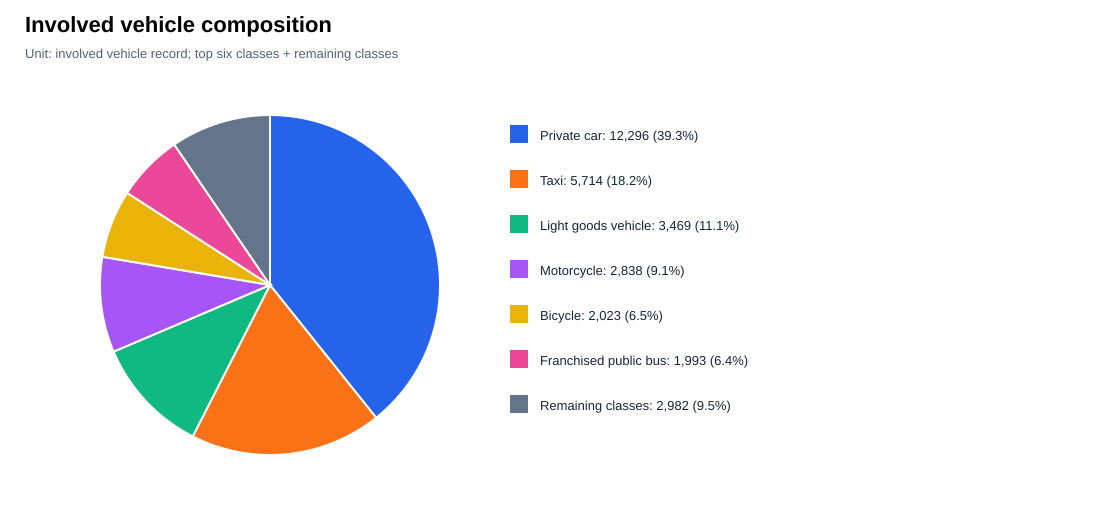

In [32]:
counts=vehicle24['Vehicle Class'].value_counts()
pie=counts.iloc[:6].copy();pie.loc['Remaining classes']=counts.iloc[6:].sum()
parts=canvas('Involved vehicle composition','Unit: involved vehicle record; top six classes + remaining classes')
angle=-math.pi/2;total=pie.sum()
for i,(label,value) in enumerate(pie.items()):
    end=angle+2*math.pi*value/total
    x1,y1=270+170*math.cos(angle),285+170*math.sin(angle)
    x2,y2=270+170*math.cos(end),285+170*math.sin(end)
    parts.append(f'<path d="M270 285 L{x1} {y1} A170 170 0 {int(end-angle>math.pi)} 1 {x2} {y2} Z" fill="{COLORS[i]}" stroke="white" stroke-width="2"/>')
    parts.append(f'<rect x="510" y="{125+i*45}" width="18" height="18" fill="{COLORS[i]}"/>')
    parts.append(text_at(540,140+i*45,f'{label}: {value:,} ({value/total:.1%})'))
    angle=end
finish(parts,'03_vehicle_class_pie.svg')


### Casualty Table · Figure 1: Line Chart of Age Distribution by Casualty Role

Ages are grouped into 10‑year bands. The horizontal axis represents ordered age groups, not a date or time trend. Separate lines represent drivers, passengers and pedestrians. Casualties with unknown age are excluded from the age curves, and their count will be stated separately. The chart shows headcounts, not risk measures.

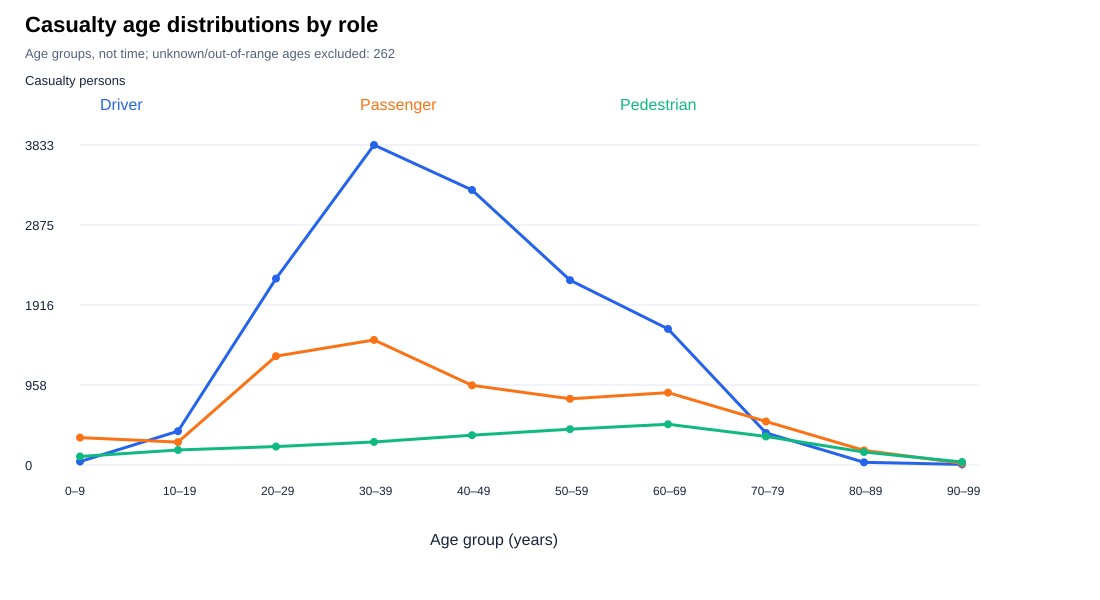

In [33]:
age_order=[f'{x}–{x+9}' for x in range(0,100,10)]
age_group=pd.cut(casualty24['Casualty Age'].astype(float),bins=list(range(0,101,10)),right=False,labels=age_order)
lines=pd.crosstab(age_group,casualty24['Role of Casualty']).reindex(age_order,fill_value=0)
parts=canvas('Casualty age distributions by role',f'Age groups, not time; unknown/out-of-range ages excluded: {age_group.isna().sum():,}',600)
maximum=max(lines.max().max(),1)
for tick in range(5):
    y=465-tick*80;parts.append(f'<path d="M80 {y} H980" stroke="#e2e8f0"/>');parts.append(text_at(25,y+5,f'{maximum*tick/4:.0f}'))
for i,label in enumerate(age_order):parts.append(text_at(65+i*98,495,label,12))
for j,col in enumerate(lines):
    points=[(80+i*98,465-float(value)/maximum*320) for i,value in enumerate(lines[col])]
    point_text=' '.join(f'{x},{y}' for x,y in points)
    parts.append(f'<polyline points="{point_text}" fill="none" stroke="{COLORS[j]}" stroke-width="3"/>')
    for x,y in points:parts.append(f'<circle cx="{x}" cy="{y}" r="4" fill="{COLORS[j]}"/>')
    parts.append(text_at(100+j*260,110,col,16,COLORS[j]))
parts.append(text_at(430,545,'Age group (years)',16));parts.append(text_at(25,85,'Casualty persons'))
finish(parts,'05_casualty_age_line.svg')


### Casualty Table · Figure 2: Stacked Percentage Chart of Injury Severity by Casualty Role

Unlike the age headcount line chart, this figure compares the injury breakdown for drivers, passengers and pedestrians. Each horizontal stacked bar totals 100%, with the denominator being all casualties of that role. Fatal injuries account for a small share, and their values are labelled fully beside the bars.

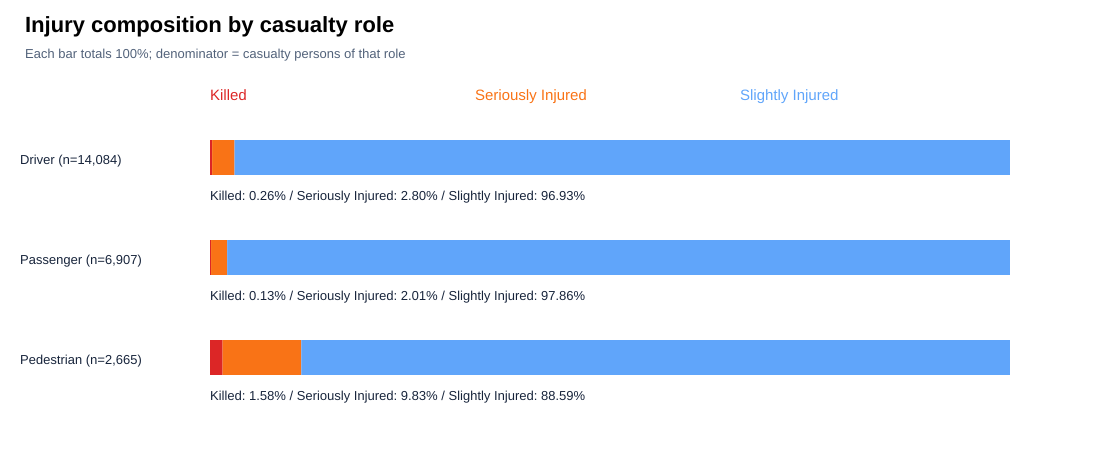

In [34]:
tab=pd.crosstab(casualty24['Role of Casualty'],casualty24['Degree of Injury']).reindex(columns=['Killed','Seriously Injured','Slightly Injured'],fill_value=0)
pct=tab.div(tab.sum(axis=1),axis=0)*100
parts=canvas('Injury composition by casualty role','Each bar totals 100%; denominator = casualty persons of that role',470)
colors=['#dc2626','#f97316','#60a5fa']
for j,col in enumerate(pct.columns):parts.append(text_at(210+j*265,100,col,15,colors[j]))
for i,(role,row) in enumerate(pct.iterrows()):
    y=140+i*100;parts.append(text_at(20,y+24,f'{role} (n={tab.loc[role].sum():,})'));x=210
    for j,value in enumerate(row):
        w=value*8;parts.append(f'<rect x="{x}" y="{y}" width="{w}" height="35" fill="{colors[j]}"/>');x+=w
    parts.append(text_at(210,y+60,' / '.join(f'{col}: {value:.2f}%' for col,value in row.items())))
finish(parts,'06_casualty_role_stacked.svg')
